## Step 1 — Configuration

In [1]:
import os

# ── Dataset path — from /kaggle/input/datasets/nishchalchandel/raf-db-face-emotion-dataset
# Kaggle mounts external datasets at /kaggle/input/<dataset-slug>
# The slug for this dataset is the last part of the path
DATASET_NAME = 'raf-db-face-emotion-dataset'
INPUT_DIR    = f'/kaggle/input/datasets/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale'

# Image settings
IMG_SIZE   = 48
CHANNELS   = 1
COLOR_MODE = 'grayscale'
BATCH_SIZE = 64

OUTPUT_DIR = '/kaggle/working'

# ── Print the full directory tree so we can confirm the structure ─────────────
print('Full structure of', INPUT_DIR)
for root, dirs, files in os.walk(INPUT_DIR):
    depth = root.replace(INPUT_DIR, '').count(os.sep)
    indent = '  ' * depth
    print(f'{indent}{os.path.basename(root)}/')
    if depth >= 2:
        dirs[:] = []

# ── Auto-detect train/, validation/, test/ ───────────────────────────────────
TRAIN_DIR = None
VAL_DIR   = None
TEST_DIR  = None

for root, dirs, files in os.walk(INPUT_DIR):
    basename = os.path.basename(root).lower()
    if basename == 'train'                  and TRAIN_DIR is None: TRAIN_DIR = root
    if basename in ('validation', 'val')    and VAL_DIR   is None: VAL_DIR   = root
    if basename == 'test'                   and TEST_DIR  is None: TEST_DIR  = root
    if TRAIN_DIR and VAL_DIR and TEST_DIR:
        break

# If no validation folder found, fall back to using test as validation
if VAL_DIR is None:
    print('⚠️  No validation/ folder found — using test/ as validation')
    VAL_DIR = TEST_DIR

assert TRAIN_DIR is not None, 'Could not find train/ folder — check dataset structure above'
assert TEST_DIR  is not None, 'Could not find test/ folder — check dataset structure above'

print('\n── Resolved paths ───────────────────')
print('Train      dir:', TRAIN_DIR)
print('Validation dir:', VAL_DIR)
print('Test       dir:', TEST_DIR)
print('Output     dir:', OUTPUT_DIR)
print('\nTrain subfolders     :', sorted(os.listdir(TRAIN_DIR)))
print('Validation subfolders:', sorted(os.listdir(VAL_DIR)))
print('Test subfolders      :', sorted(os.listdir(TEST_DIR)))

Full structure of /kaggle/input/datasets/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale
balanced-raf-db-dataset-7575-grayscale/
  val/
    surprise/
    fear/
    angry/
    neutral/
    sad/
    disgust/
    happy/
  test/
    surprise/
    fear/
    angry/
    neutral/
    sad/
    disgust/
    happy/
  train/
    surprise/
    fear/
    angry/
    neutral/
    sad/
    disgust/
    happy/

── Resolved paths ───────────────────
Train      dir: /kaggle/input/datasets/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale/train
Validation dir: /kaggle/input/datasets/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale/val
Test       dir: /kaggle/input/datasets/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale/test
Output     dir: /kaggle/working

Train subfolders     : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Validation subfolders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Test subfolders      : ['angry', 'disg

## Step 2 — Check GPU

In [2]:
import tensorflow as tf

print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs available:', gpus)

if gpus:
    print('✅ GPU detected — training will be fast!')
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print('⚠️  No GPU detected. Go to Settings → Accelerator → GPU T4 x2')

2026-03-20 21:01:28.374259: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774040488.559585      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774040488.616127      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774040489.104284      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774040489.104332      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774040489.104335      23 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
✅ GPU detected — training will be fast!


## Step 3 — Imports

In [3]:
import glob
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import load_img, ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Dense, Conv2D, Dropout, Flatten,
    MaxPooling2D, BatchNormalization
)
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers import Adam

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print('All imports successful.')

All imports successful.


## Step 4 — Build Dataset Dataframes

In [4]:
def build_dataframe(img_dir):
    image_paths, labels = [], []
    for emotion in sorted(os.listdir(img_dir)):
        emotion_dir = os.path.join(img_dir, emotion)
        if not os.path.isdir(emotion_dir):
            continue
        count = 0
        for imagename in os.listdir(emotion_dir):
            if imagename.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(emotion_dir, imagename))
                labels.append(emotion.lower())
                count += 1
        print(f'  {emotion:<10}: {count} images')
    return image_paths, labels

print('Building train dataframe...')
train_images, train_labels = build_dataframe(TRAIN_DIR)
train_df = pd.DataFrame({'image': train_images, 'label': train_labels})

print('\nBuilding validation dataframe...')
val_images, val_labels = build_dataframe(VAL_DIR)
val_df = pd.DataFrame({'image': val_images, 'label': val_labels})

print('\nBuilding test dataframe...')
test_images, test_labels = build_dataframe(TEST_DIR)
test_df = pd.DataFrame({'image': test_images, 'label': test_labels})

print('\n── Summary ──────────────────────────')
print('Train      samples:', len(train_df))
print('Validation samples:', len(val_df))
print('Test       samples:', len(test_df))
print('Classes:', sorted(train_df['label'].unique()))

Building train dataframe...
  angry     : 4289 images
  disgust   : 4289 images
  fear      : 4289 images
  happy     : 4289 images
  neutral   : 4289 images
  sad       : 4289 images
  surprise  : 4289 images

Building validation dataframe...
  angry     : 1072 images
  disgust   : 1072 images
  fear      : 1072 images
  happy     : 1072 images
  neutral   : 1072 images
  sad       : 1072 images
  surprise  : 1072 images

Building test dataframe...
  angry     : 595 images
  disgust   : 595 images
  fear      : 595 images
  happy     : 595 images
  neutral   : 595 images
  sad       : 595 images
  surprise  : 595 images

── Summary ──────────────────────────
Train      samples: 30023
Validation samples: 7504
Test       samples: 4165
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## Step 5 — Extract Features & Normalise

In [5]:
def extract_features(images):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode=COLOR_MODE, target_size=(IMG_SIZE, IMG_SIZE))
        features.append(np.array(img))
    return np.array(features).reshape(-1, IMG_SIZE, IMG_SIZE, CHANNELS)

print('Extracting train features...')
x_train = extract_features(train_df['image']) / 255.0

print('Extracting validation features...')
x_val = extract_features(val_df['image']) / 255.0

print('Extracting test features...')
x_test = extract_features(test_df['image']) / 255.0

print('x_train shape:', x_train.shape)
print('x_val   shape:', x_val.shape)
print('x_test  shape:', x_test.shape)

Extracting train features...


100%|██████████| 30023/30023 [03:36<00:00, 138.40it/s]


Extracting validation features...


100%|██████████| 7504/7504 [01:00<00:00, 123.82it/s]


Extracting test features...


100%|██████████| 4165/4165 [00:31<00:00, 133.77it/s]

x_train shape: (30023, 48, 48, 1)
x_val   shape: (7504, 48, 48, 1)
x_test  shape: (4165, 48, 48, 1)


## Step 6 — Encode Labels

In [6]:
le = LabelEncoder()
le.fit(train_df['label'])

y_train = to_categorical(le.transform(train_df['label']), num_classes=7)
y_val   = to_categorical(le.transform(val_df['label']),   num_classes=7)
y_test  = to_categorical(le.transform(test_df['label']),  num_classes=7)

print('Label classes (index order used by model):', list(le.classes_))
print('y_train shape:', y_train.shape)

with open(os.path.join(OUTPUT_DIR, 'label_classes.json'), 'w') as f:
    json.dump(list(le.classes_), f)
print('Label classes saved to label_classes.json')

Label classes (index order used by model): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
y_train shape: (30023, 7)
Label classes saved to label_classes.json


## Step 7 — Data Augmentation

In [7]:
datagen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='nearest'
)

datagen.fit(x_train)
print('Data augmentation configured.')

Data augmentation configured.


## Step 8 — Build or Resume Model

In [8]:
checkpoint_dir = os.path.join(OUTPUT_DIR, 'checkpoints')
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_files = glob.glob(os.path.join(checkpoint_dir, '*.h5'))
start_epoch = 0

if checkpoint_files:
    latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    print('Resuming from:', latest_checkpoint)
    model = load_model(latest_checkpoint, compile=False)
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    match = re.search(r'facialemotionmodel(\d+)_', os.path.basename(latest_checkpoint))
    if match:
        start_epoch = int(match.group(1))
    print('Resuming from epoch:', start_epoch)

else:
    print('No checkpoint found — building model from scratch')
    model = Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS)),

        # Block 1
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 24×24
        Dropout(0.25),

        # Block 2
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 12×12
        Dropout(0.25),

        # Block 3
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 6×6
        Dropout(0.25),

        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.4),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(7, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

No checkpoint found — building model from scratch


I0000 00:00:1774040827.047865      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774040827.054460      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,225,735 (19.93 MB)

 Trainable params: 5,223,815 (19.93 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Step 9 — Train

In [9]:
checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir, 'facialemotionmodel{epoch:02d}_valacc{val_accuracy:.4f}.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

early_stop_cb = EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    datagen.flow(x_train, y_train, batch_size=BATCH_SIZE),
    steps_per_epoch=len(x_train) // BATCH_SIZE,
    epochs=100,
    initial_epoch=start_epoch,
    validation_data=(x_val, y_val),
    callbacks=[checkpoint_cb, reduce_lr_cb, early_stop_cb]
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1774040832.905852      68 service.cc:152] XLA service 0x7afc14002560 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774040832.905889      68 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774040832.905893      68 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774040833.597886      68 cuda_dnn.cc:529] Loaded cuDNN version 91002


  5/469 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.1233 - loss: 3.1572

I0000 00:00:1774040841.162257      68 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2382 - loss: 2.2374
Epoch 1: val_accuracy improved from -inf to 0.18710, saving model to /kaggle/working/checkpoints/facialemotionmodel01_valacc0.1871.h5


...

469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8326 - loss: 0.4541 - val_accuracy: 0.9027 - val_loss: 0.2675 - learning_rate: 1.2500e-04
Epoch 78/100
  1/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.7812 - loss: 0.5326
Epoch 78: val_accuracy improved from 0.90272 to 0.90312, saving model to /kaggle/working/checkpoints/facialemotionmodel78_valacc0.9031.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7812 - loss: 0.5326 - val_accuracy: 0.9031 - val_loss: 0.2665 - learning_rate: 1.2500e-04
Epoch 79/100
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8352 - loss: 0.4507
Epoch 79: val_accuracy did not improve from 0.90312
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8352 - loss: 0.4507 - val_accuracy: 0.9001 - val_loss: 0.2785 - learning_rate: 1.2500e-04
Epoch 80/100
  1/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8438 - loss: 0.4306
Epoch 80: val_accuracy did not improve from 0.90312
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8438 - loss: 0.4306 - val_accuracy: 0.9003 - val_loss: 0.2766 - learning_rate: 1.2500e-04
Epoch 81/100
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8406 - loss: 0.4403
Epoch 81: val_accuracy did not improve from 0.90312
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.8406 - loss: 0.4403 - val_accuracy: 0.8901 - val_loss: 0.3054 - learning_rate: 1.25

469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8392 - loss: 0.4452 - val_accuracy: 0.9090 - val_loss: 0.2510 - learning_rate: 6.2500e-05
Epoch 86/100
  1/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8125 - loss: 0.4874
Epoch 86: val_accuracy improved from 0.90898 to 0.90925, saving model to /kaggle/working/checkpoints/facialemotionmodel86_valacc0.9092.h5


469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8125 - loss: 0.4874 - val_accuracy: 0.9092 - val_loss: 0.2508 - learning_rate: 6.2500e-05
Epoch 87/100
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8333 - loss: 0.4513
Epoch 87: val_accuracy did not improve from 0.90925
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.8333 - loss: 0.4513 - val_accuracy: 0.9021 - val_loss: 0.2725 - learning_rate: 6.2500e-05
Epoch 88/100
  1/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.8438 - loss: 0.4422
Epoch 88: val_accuracy did not improve from 0.90925
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8438 - loss: 0.4422 - val_accuracy: 0.9019 - val_loss: 0.2734 - learning_rate: 6.2500e-05
Epoch 89/100
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8421 - loss: 0.4340
Epoch 89: val_accuracy did not improve from 0.90925
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.8421 - loss: 0.4340 - val_accuracy: 0.9053 - val_loss: 0.2639 - learning_rate: 6.25

469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8410 - loss: 0.4364 - val_accuracy: 0.9119 - val_loss: 0.2494 - learning_rate: 6.2500e-05
Epoch 92/100
  1/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8281 - loss: 0.4392
Epoch 92: val_accuracy did not improve from 0.91191
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8281 - loss: 0.4392 - val_accuracy: 0.9111 - val_loss: 0.2499 - learning_rate: 6.2500e-05
Epoch 93/100
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8473 - loss: 0.4292
Epoch 93: val_accuracy did not improve from 0.91191
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.8473 - loss: 0.4292 - val_accuracy: 0.9100 - val_loss: 0.2526 - learning_rate: 6.2500e-05
Epoch 94/100
  1/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.7812 - loss: 0.5679
Epoch 94: val_accuracy did not improve from 0.91191
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7812 - loss: 0.5679 - val_accuracy: 0.9102 - val_loss: 0.2523 - learning_rate: 6.25

## Step 10 — Save Final Model

In [10]:
model_json = model.to_json()
with open(os.path.join(OUTPUT_DIR, 'facialemotionmodel.json'), 'w') as f:
    f.write(model_json)

model.save_weights(os.path.join(OUTPUT_DIR, 'facialemotionmodel.weights.h5'))
model.save(os.path.join(OUTPUT_DIR, 'facialemotionmodel.h5'))

print('✅ Files saved to /kaggle/working/:')
for f in os.listdir(OUTPUT_DIR):
    fpath = os.path.join(OUTPUT_DIR, f)
    if os.path.isfile(fpath):
        size_mb = os.path.getsize(fpath) / (1024 * 1024)
        print(f'  {f}  ({size_mb:.1f} MB)')

✅ Files saved to /kaggle/working/:
  facialemotionmodel.h5  (59.9 MB)
  facialemotionmodel.weights.h5  (59.9 MB)
  label_classes.json  (0.0 MB)
  __notebook__.ipynb  (5.6 MB)
  facialemotionmodel.json  (0.0 MB)


## Step 11 — Evaluate on Test Set

In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)
print(f'\n── Final Test Results ───────────────')
print(f'Test accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)')
print(f'Test loss     : {test_loss:.4f}')

131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9422 - loss: 0.1743

── Final Test Results ───────────────
Test accuracy : 0.9107 (91.07%)
Test loss     : 0.2597


## Step 12 — Plot Training History

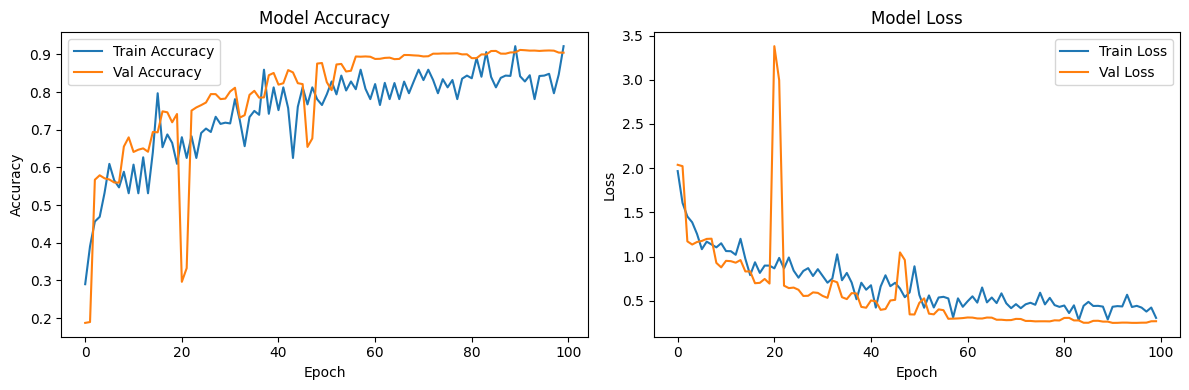

Training complete!


In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],     label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_history.png'))
plt.show()
print('Training complete!')